In [1]:
from pathlib import Path
import sys
import os
import csv
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

PROJECT_ROOT = Path(r"D:\RetailMind-AI")
NOTEBOOK_DIR = PROJECT_ROOT / "Notebooks"
OUTPUT_DIR = PROJECT_ROOT / "Outputs" / "Day-09"
CROPS_DIR = OUTPUT_DIR / "detected_objects"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CROPS_DIR.mkdir(parents=True, exist_ok=True)

print("Python executable:", sys.executable)
print("Project root exists:", PROJECT_ROOT.exists())
print("Output folder:", OUTPUT_DIR)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python executable: D:\retailmind_env\Scripts\python.exe
Project root exists: True
Output folder: D:\RetailMind-AI\Outputs\Day-09
OpenCV: 5.1.0
NumPy: 2.5.4
Pandas: 3.1.1


In [4]:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cpu

Looking in indexes: https://download.pytorch.org/whl/cpu
   ---------------------------------------- 0.0/126.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/126.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/126.6 MB ? eta -:--:--
   ---------------------------------------- 0.5/126.6 MB 932.9 kB/s eta 0:02:16
   ---------------------------------------- 0.8/126.6 MB 1.0 MB/s eta 0:02:01
   ---------------------------------------- 0.8/126.6 MB 1.0 MB/s eta 0:02:01
   ---------------------------------------- 1.0/126.6 MB 1.0 MB/s eta 0:02:00
   ---------------------------------------- 1.3/126.6 MB 1.0 MB/s eta 0:02:02
   ---------------------------------------- 1.6/126.6 MB 987.0 kB/s eta 0:02:07
   ---------------------------------------- 1.6/126.6 MB 987.0 kB/s eta 0:02:07
   ---------------------------------------- 1.6/126.6 MB 987.0 kB/s eta 0:02:07
   ---------------------------------------- 1.6/126.6 MB 987.0 kB/s eta 0:02:07
   ---------------

In [5]:
%pip install ultralytics

   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.5 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.5 MB ? eta -:--:--
   -------------- ------------------------- 0.5/1.5 MB 882.6 kB/s eta 0:00:02
   -------------- ------------------------- 0.5/1.5 MB 882.6 kB/s eta 0:00:02
   -------------- ------------------------- 0.5/1.5 MB 882.6 kB/s eta 0:00:02
   -------------- ------------------------- 0.5/1.5 MB 882.6 kB/s eta 0:00:02
   -------------- ------------------------- 0.5/1.5 MB 882.6 kB/s eta 0:00:02
   -------------- ------------------------- 0.5/1.5 MB 882.6 kB/s eta 0:00:02
   -------------- ------------------------- 0.5/1.5 MB 882.6 kB/s eta 0:00:02
   -------------- ------------------------- 0.5/1.5 MB 882.6 kB/s eta 0:00:02
   -------------- ------------------------- 0.5/1.5 MB 882.6 kB/s eta 0:00:02
   -------------- ------------------------- 0.5/1.5 MB 882.6 kB/s eta 0:00:02
   ----------

In [6]:
try:
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
except ImportError as exc:
    raise ImportError(
        "PyTorch is not installed in this Jupyter kernel. "
        "Install a compatible PyTorch build, restart the kernel, and rerun."
    ) from exc

try:
    import ultralytics
    from ultralytics import YOLO
    print("Ultralytics:", ultralytics.__version__)
except ImportError as exc:
    raise ImportError(
        "Ultralytics is not installed in this Jupyter kernel. "
        "Run %pip install ultralytics, restart the kernel, and rerun."
    ) from exc

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Selected inference device:", DEVICE)

PyTorch: 2.15.0+cpu
CUDA available: False
Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\HP\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.218
Selected inference device: cpu


## 4. Load a pretrained YOLO model

We use the small pretrained YOLOv8 model (`yolov8n.pt`) as a practical starting point. The first run may download model weights, so an internet connection may be required.

This is inference with pretrained weights—not training a model on your RetailMind data.

In [7]:
MODEL_NAME = "yolov8n.pt"

model = YOLO(MODEL_NAME)

print("YOLO model loaded:", MODEL_NAME)
print("Number of class labels:", len(model.names))
print("Example class labels:", list(model.names.items())[:10])

YOLO model loaded: yolov8n.pt
Number of class labels: 80
Example class labels: [(0, 'person'), (1, 'bicycle'), (2, 'car'), (3, 'motorcycle'), (4, 'airplane'), (5, 'bus'), (6, 'train'), (7, 'truck'), (8, 'boat'), (9, 'traffic light')]


## 5. Choose an input image

Set `IMAGE_PATH` to a real image on your computer. For best results, use a clear photo with several everyday objects or a retail/shelf scene.

If you leave `IMAGE_PATH` as `None`, the cell downloads the Ultralytics sample `bus.jpg` into `Data/Day-09/`. This sample is only a technical demo image, not a retail dataset.

Supported common formats include JPG, JPEG, and PNG.

Using image: D:\RetailMind-AI\Data\Day-09\bus.jpg


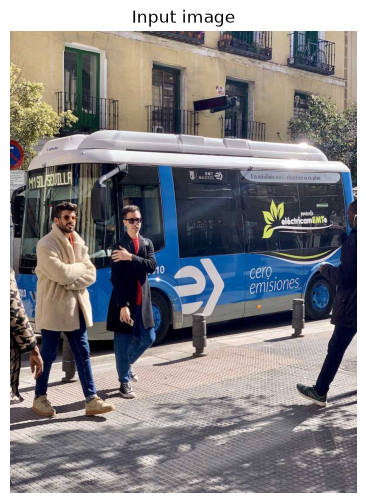

In [8]:
# OPTION A: Set this to your own image path, for example:
# IMAGE_PATH = r"D:\RetailMind-AI\Data\your_retail_photo.jpg"

IMAGE_PATH = None

if IMAGE_PATH is None:
    sample_dir = PROJECT_ROOT / "Data" / "Day-09"
    sample_dir.mkdir(parents=True, exist_ok=True)
    image_path = sample_dir / "bus.jpg"

    if not image_path.exists():
        from urllib.request import urlretrieve
        sample_url = "https://ultralytics.com/images/bus.jpg"
        print("Downloading a sample image...")
        urlretrieve(sample_url, image_path)
else:
    image_path = Path(IMAGE_PATH)

if not image_path.exists():
    raise FileNotFoundError(f"Input image not found: {image_path}")

print("Using image:", image_path)

image_bgr = cv2.imread(str(image_path))
if image_bgr is None:
    raise ValueError("OpenCV could not read this image. Check the path and file format.")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(image_rgb)
plt.title("Input image")
plt.axis("off")
plt.show()

## 6. Run YOLO object detection

`conf` sets the minimum confidence threshold. `iou` is the IoU threshold used during NMS. These values affect which detections remain.

Try changing `CONF_THRESHOLD` (for example, 0.25 or 0.40) and compare the number of detections.

In [9]:
CONF_THRESHOLD = 0.25
NMS_IOU_THRESHOLD = 0.45

results = model.predict(
    source=str(image_path),
    conf=CONF_THRESHOLD,
    iou=NMS_IOU_THRESHOLD,
    device=DEVICE,
    verbose=False
)

result = results[0]
print("Inference complete.")
print("Image dimensions (height, width):", result.orig_shape)
print("Number of detections:", len(result.boxes))

Inference complete.
Image dimensions (height, width): (1080, 810)
Number of detections: 6


## 7. Visualize the detections

The annotated image includes the predicted class label, confidence, and bounding box.

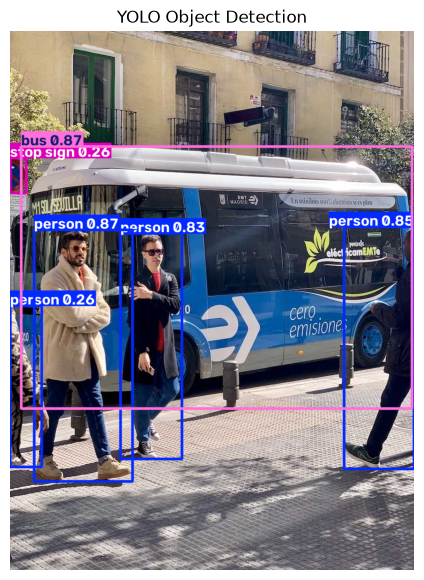

Saved: D:\RetailMind-AI\Outputs\Day-09\yolo_detection.png


In [10]:
annotated_bgr = result.plot()
annotated_rgb = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 7))
plt.imshow(annotated_rgb)
plt.title("YOLO Object Detection")
plt.axis("off")
plt.show()

annotated_path = OUTPUT_DIR / "yolo_detection.png"
cv2.imwrite(str(annotated_path), annotated_bgr)
print("Saved:", annotated_path)

## 8. Extract bounding boxes, confidence, and class labels

YOLO returns box coordinates in `xyxy` format:
- `x1, y1`: top-left corner.
- `x2, y2`: bottom-right corner.

Coordinates are pixel positions in the original image. The confidence is not a guarantee that a prediction is correct; inspect detections visually.

In [11]:
detection_rows = []

for box in result.boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().tolist()
    confidence = float(box.conf[0].cpu().item())
    class_id = int(box.cls[0].cpu().item())
    class_name = model.names[class_id]

    detection_rows.append({
        "class_id": class_id,
        "class_name": class_name,
        "confidence": confidence,
        "x1": round(x1, 2),
        "y1": round(y1, 2),
        "x2": round(x2, 2),
        "y2": round(y2, 2),
        "box_width": round(x2 - x1, 2),
        "box_height": round(y2 - y1, 2)
    })

detections_df = pd.DataFrame(
    detection_rows,
    columns=[
        "class_id", "class_name", "confidence",
        "x1", "y1", "x2", "y2", "box_width", "box_height"
    ]
)

display(detections_df.head(20))
print("Total detections:", len(detections_df))

,class_id,class_name,confidence,x1,y1,x2,y2,box_width,box_height
0,5,bus,0.873448,22.87,231.28,805.00,756.84,782.13,525.56
1,0,person,0.865691,48.55,398.55,245.35,902.70,196.80,504.15
2,0,person,0.852836,669.47,392.19,809.72,877.04,140.25,484.85
3,0,person,0.825225,221.52,405.80,344.97,857.54,123.45,451.74
4,0,person,0.261112,0.00,550.53,63.01,873.44,63.01,322.92
5,11,stop sign,0.255069,0.06,254.46,32.56,324.87,32.50,70.41


Total detections: 6


## 9. Save detection results as CSV

The CSV can be used later for analysis, filtering, and reporting.

In [12]:
csv_path = OUTPUT_DIR / "detection_results.csv"
detections_df.to_csv(csv_path, index=False)
print("Saved detection table:", csv_path)

Saved detection table: D:\RetailMind-AI\Outputs\Day-09\detection_results.csv


## 10. Crop each detected object

This section saves each detected bounding-box crop separately. Crops are based on model predictions, so they may contain partial objects or background.

The original image is loaded in BGR format by OpenCV; crop coordinates are clipped to image boundaries.

In [13]:
height, width = image_bgr.shape[:2]
saved_crops = []

for index, row in detections_df.iterrows():
    x1 = max(0, int(np.floor(row["x1"])))
    y1 = max(0, int(np.floor(row["y1"])))
    x2 = min(width, int(np.ceil(row["x2"])))
    y2 = min(height, int(np.ceil(row["y2"])))

    crop = image_bgr[y1:y2, x1:x2]
    if crop.size == 0:
        continue

    safe_name = "".join(
        ch if ch.isalnum() or ch in ("-", "_") else "_"
        for ch in str(row["class_name"])
    )
    crop_path = CROPS_DIR / f"{index:03d}_{safe_name}.jpg"
    cv2.imwrite(str(crop_path), crop)
    saved_crops.append(crop_path)

print(f"Saved {len(saved_crops)} object crops to:", CROPS_DIR)

Saved 6 object crops to: D:\RetailMind-AI\Outputs\Day-09\detected_objects


## 11. Detection summary

Count how many detections were predicted for each class. This is a count of detections in this one image—not a complete inventory count and not proof of stock quantity.

,detection_count
class_name,
person,4
bus,1
stop sign,1


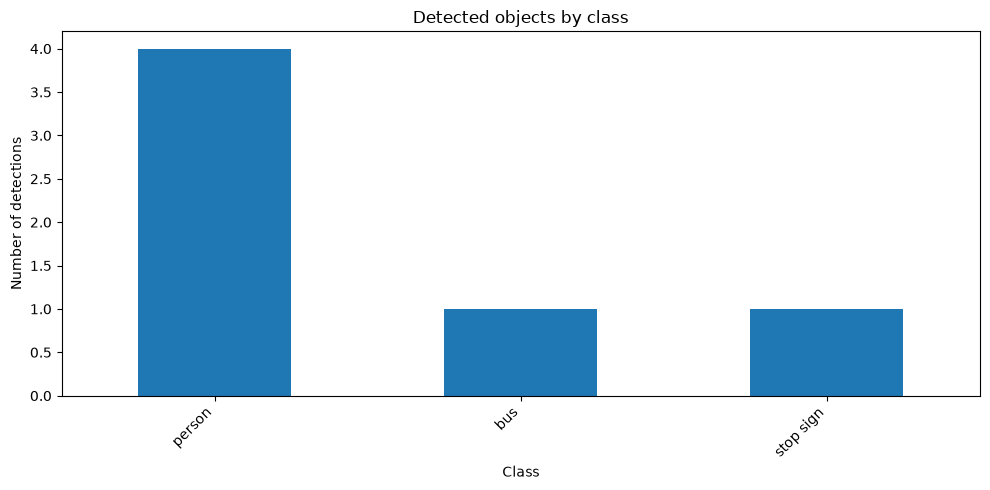

<Figure size 640x480 with 0 Axes>

Saved summary: D:\RetailMind-AI\Outputs\Day-09\detection_summary.png


In [14]:
if len(detections_df) == 0:
    print("No objects detected. Try a different image or lower CONF_THRESHOLD.")
else:
    class_counts = (
        detections_df.groupby("class_name")
        .size()
        .sort_values(ascending=False)
    )

    display(class_counts.rename("detection_count").to_frame())

    plt.figure(figsize=(10, 5))
    class_counts.plot(kind="bar")
    plt.title("Detected objects by class")
    plt.xlabel("Class")
    plt.ylabel("Number of detections")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    summary_path = OUTPUT_DIR / "detection_summary.png"
    plt.savefig(summary_path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved summary:", summary_path)

## 12. Understand IoU with a simple numerical example

Use two boxes to calculate IoU manually. This example uses boxes in `[x1, y1, x2, y2]` format.

Box A = `(10, 10, 50, 50)`  
Box B = `(30, 30, 70, 70)`

Work out:
- Area of A.
- Area of B.
- Intersection width and height.
- Intersection area.
- Union area.
- IoU.

Then compare your result with the code.

In [15]:
box_a = (10, 10, 50, 50)
box_b = (30, 30, 70, 70)

def calculate_iou(box1, box2):
    x_left = max(box1[0], box2[0])
    y_top = max(box1[1], box2[1])
    x_right = min(box1[2], box2[2])
    y_bottom = min(box1[3], box2[3])

    intersection_width = max(0, x_right - x_left)
    intersection_height = max(0, y_bottom - y_top)
    intersection_area = intersection_width * intersection_height

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union_area = area1 + area2 - intersection_area
    return intersection_area / union_area if union_area else 0.0

iou_value = calculate_iou(box_a, box_b)
print("IoU:", round(iou_value, 4))

IoU: 0.1429


## 14. Save a run summary and verify outputs

This writes a small JSON summary and lists all generated files.

In [16]:
run_summary = {
    "model": MODEL_NAME,
    "input_image": str(image_path),
    "confidence_threshold": CONF_THRESHOLD,
    "nms_iou_threshold": NMS_IOU_THRESHOLD,
    "device": str(DEVICE),
    "detection_count": int(len(detections_df)),
    "detected_classes": (
        detections_df["class_name"].value_counts().to_dict()
        if len(detections_df) else {}
    )
}

summary_json_path = OUTPUT_DIR / "run_summary.json"
with open(summary_json_path, "w", encoding="utf-8") as file:
    json.dump(run_summary, file, indent=4)

print("Day 09 run summary saved:", summary_json_path)
print("\nFiles currently in Day-09 output folder:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print("-", path.relative_to(OUTPUT_DIR))

Day 09 run summary saved: D:\RetailMind-AI\Outputs\Day-09\run_summary.json

Files currently in Day-09 output folder:
- detected_objects\000_bus.jpg
- detected_objects\001_person.jpg
- detected_objects\002_person.jpg
- detected_objects\003_person.jpg
- detected_objects\004_person.jpg
- detected_objects\005_stop_sign.jpg
- detection_results.csv
- detection_summary.png
- run_summary.json
- yolo_detection.png
